### Лабораторная работа №2: Классификация

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
#warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

In [2]:
url = "https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset/Titanic-Dataset.csv"
df = pd.read_csv(url, sep=',')

print("Общий размер объединенного датасета:", df.shape)
display(df.head())
df.info()

Общий размер объединенного датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Размер датасета: (891, 12)

Типы признаков:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Пропуски по столбцам:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

Дубликаты строк: 0


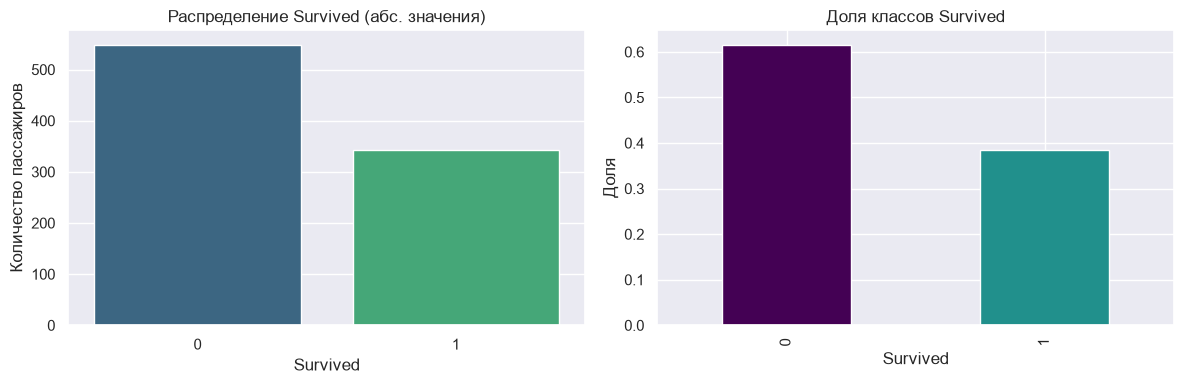


Доли классов:
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


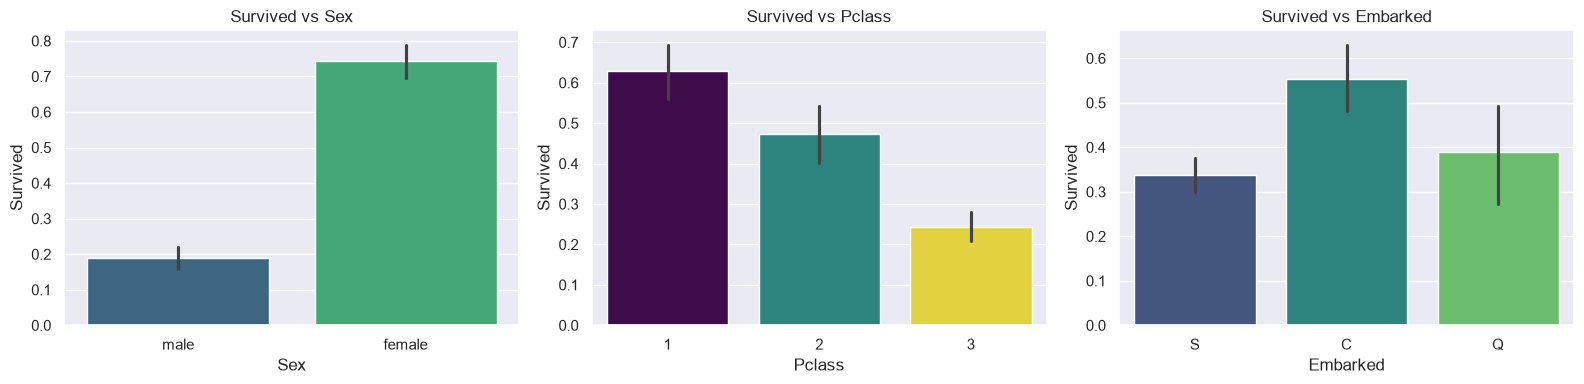

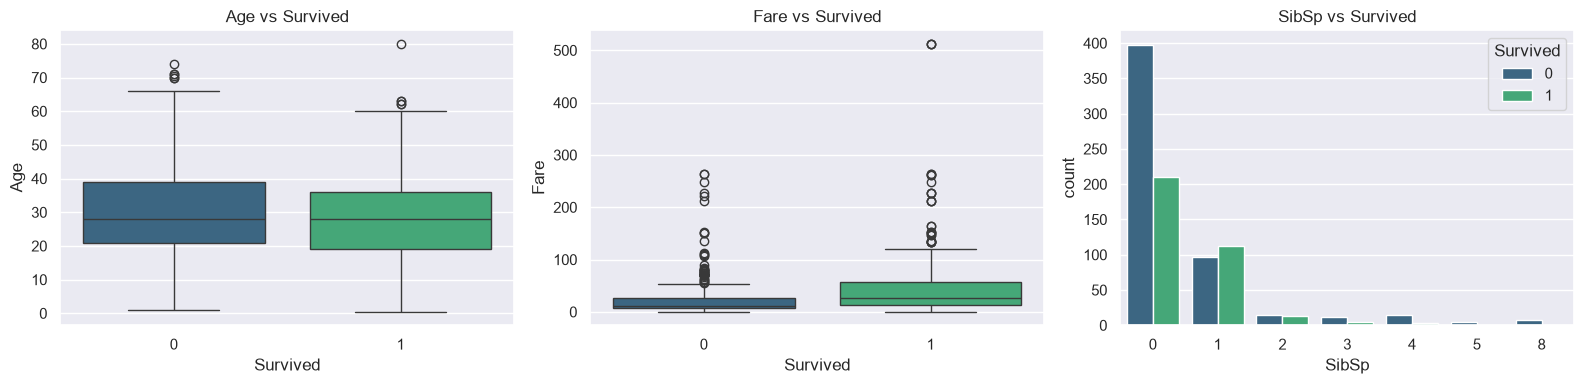

In [3]:
# --- 1.1. Структура данных и типы признаков ---
print("Размер датасета:", df.shape)
print("\nТипы признаков:")
print(df.dtypes)
print("\nПропуски по столбцам:")
print(df.isna().sum().sort_values(ascending=False))
print("\nДубликаты строк:", df.duplicated().sum())

# --- 1.2. Распределение целевой переменной ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Survived', palette='viridis', ax=axes[0], hue='Survived', legend=False)
axes[0].set_title('Распределение Survived (абс. значения)')
axes[0].set_xlabel('Survived'); axes[0].set_ylabel('Количество пассажиров')

df['Survived'].value_counts(normalize=True).plot(
    kind='bar', color=['#440154', '#21908C'], ax=axes[1])
axes[1].set_title('Доля классов Survived')
axes[1].set_ylabel('Доля'); axes[1].set_xlabel('Survived')
plt.tight_layout(); plt.show()

print("\nДоли классов:")
print(df['Survived'].value_counts(normalize=True).round(4))

# --- 1.3. Связь ключевых признаков с целевой ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df, x='Sex', y='Survived', palette='viridis', ax=axes[0], hue='Sex', legend=False)
axes[0].set_title('Survived vs Sex')
sns.barplot(data=df, x='Pclass', y='Survived', palette='viridis', ax=axes[1], hue='Pclass', legend=False)
axes[1].set_title('Survived vs Pclass')
sns.barplot(data=df, x='Embarked', y='Survived', palette='viridis', ax=axes[2], hue='Embarked', legend=False)
axes[2].set_title('Survived vs Embarked')
plt.tight_layout(); plt.show()

# --- 1.4. Числовые признаки vs выживание ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='Survived', y='Age', palette='viridis', ax=axes[0], hue='Survived', legend=False)
axes[0].set_title('Age vs Survived')
sns.boxplot(data=df, x='Survived', y='Fare', palette='viridis', ax=axes[1], hue='Survived', legend=False)
axes[1].set_title('Fare vs Survived')
sns.countplot(data=df, x='SibSp', hue='Survived', palette='viridis', ax=axes[2])
axes[2].set_title('SibSp vs Survived')
plt.tight_layout(); plt.show()

## 1. Первичный анализ данных

Датасет Titanic содержит 891 запись и 12 признаков. Целевая переменная — `Survived` (0/1).

**Пропуски:** `Cabin` (687), `Age` (177), `Embarked` (2). Дубликатов строк нет — данные чистые по структуре, но требуют обработки пропусков.

**Признаки-«ловушки»**, которые нужно удалить до обучения, чтобы модель не запоминала конкретных пассажиров:
- `PassengerId` — технический идентификатор, не несёт информации о пассажире;
- `Name`, `Ticket`, `Cabin` — почти уникальны для каждого пассажира. Если их оставить, дерево/лес могут «выучить» конкретные значения и показать завышенное качество на train, но провалиться на новых данных. Это классическая утечка информации (data leakage).

**Целевая переменная несбалансирована:** ~62% погибших, ~38% выживших. Поэтому Accuracy сама по себе обманчива: модель, всегда предсказывающая «погиб», уже даёт 62% Accuracy, но бесполезна. Основная метрика — **F1 для класса `Survived=1`**, потому что она балансирует Precision и Recall и лучше отражает качество на несбалансированных классах.

**Связь признаков с целевой:** женщины выживали заметно чаще мужчин, пассажиры 1-го класса — чаще 3-го, а пассажиры из Cherbourg (`Embarked=C`) — чаще остальных. Это ожидаемо и подтверждает, что `Sex`, `Pclass`, `Embarked` — сильные предикторы.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# --- 2.1. Удаляем признаки-«ловушки» ---
df_model = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# --- 2.2. Выделяем X и y ---
X = df_model.drop(columns='Survived')
y = df_model['Survived']

print("Признаки после удаления ловушек:", X.columns.tolist())
print("Размер X:", X.shape)

# --- 2.3. Разбиение train/test со стратификацией ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain: {X_train.shape[0]}, Test: {X_test.shape[0]}")
print("Доли классов в train:")
print(y_train.value_counts(normalize=True).round(4))
print("Доли классов в test:")
print(y_test.value_counts(normalize=True).round(4))

# --- 2.4. Списки колонок ---
num_features = ["Age", "Fare", "SibSp", "Parch"]
cat_features = ["Pclass", "Sex", "Embarked"]

# --- 2.5. Препроцессор для деревьев (БЕЗ масштабирования) ---
preprocess_tree = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

# --- 2.6. Препроцессор для SVM/KNN (С масштабированием) ---
preprocess_scaled = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])

# --- 2.7. Проверка, что препроцессоры работают и не текут ---
# fit только на train, transform на train и test
X_train_tree = preprocess_tree.fit_transform(X_train)
X_test_tree  = preprocess_tree.transform(X_test)
print("\nРазмер X_train после preprocess_tree: ", X_train_tree.shape)
print("Размер X_test  после preprocess_tree: ", X_test_tree.shape)

feature_names_out = preprocess_tree.get_feature_names_out()
print("\nИтоговые признаки после препроцессинга:")
for i, name in enumerate(feature_names_out):
    print(f"  {i}: {name}")

Признаки после удаления ловушек: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Размер X: (891, 7)

Train: 712, Test: 179
Доли классов в train:
Survived
0    0.6166
1    0.3834
Name: proportion, dtype: float64
Доли классов в test:
Survived
0    0.6145
1    0.3855
Name: proportion, dtype: float64

Размер X_train после preprocess_tree:  (712, 12)
Размер X_test  после preprocess_tree:  (179, 12)

Итоговые признаки после препроцессинга:
  0: num__Age
  1: num__Fare
  2: num__SibSp
  3: num__Parch
  4: cat__Pclass_1
  5: cat__Pclass_2
  6: cat__Pclass_3
  7: cat__Sex_female
  8: cat__Sex_male
  9: cat__Embarked_C
  10: cat__Embarked_Q
  11: cat__Embarked_S


## 2. Подготовка данных

**Обработка пропусков:**
- `Age` (177 пропусков) — заполняем медианой. Медиана устойчива к выбросам, а возраст имеет скошенное распределение (много молодых, мало пожилых);
- `Embarked` (2 пропуска) — заполняем модой (самое частое значение `S`), так как категориальный признак;
- `Cabin` — удалён, потому что пропущено ~77% значений. Восстанавливать его по `Ticket`/`Fare` — это уже отдельная задача, и на оставшихся 23% модель будет переобучаться.

**Кодирование категориальных признаков:** One-Hot Encoding для `Pclass`, `Sex`, `Embarked`. Эти признаки номинальные (нет естественного порядка между `S`, `C`, `Q`), поэтому порядковое кодирование ввело бы ложную иерархию. `handle_unknown="ignore"` защищает от падения, если в test встретится категория, которой не было в train.

**Масштабирование:** `StandardScaler` применяется **только для SVM и KNN**. Причина: SVM строит разделяющую гиперплоскость по скалярным произведениям, а KNN — по евклидову расстоянию. Если `Age` меняется в диапазоне 0–80, а `Fare` — 0–500, то `Fare` будет доминировать в расстоянии, и `Age` фактически «потеряется». Деревья и ансамбли (DT, RF, GB) масштабирование не требуют: они сравнивают признаки по порогам, а не по абсолютным величинам.

**Разбиение:** `train_test_split(test_size=0.2, stratify=y, random_state=42)` — 712 / 179 объектов, доли классов сохранены в обеих частях. Стратификация критична: без неё в test могло оказаться, например, 30% выживших вместо 38%, и метрики были бы несопоставимы.

**Защита от data leakage:** все преобразования (импутация, OHE, масштабирование) обёрнуты в `Pipeline`/`ColumnTransformer` и обучаются **только на train**. `fit_transform` на train, `transform` на test. Это гарантирует, что тестовая выборка не влияет на параметры препроцессинга.

## 3. Dummy baseline

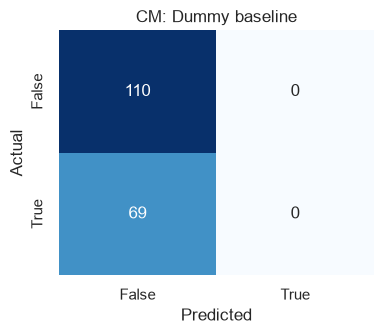

Dummy baseline:
  Model     : Dummy baseline
  Accuracy  : 0.6145251396648045
  Precision : 0.0
  Recall    : 0.0
  F1        : 0.0
  ROC_AUC   : 0.5


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.0,0.0,0.0,0.5


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# --- 3.1. Dummy baseline: всегда предсказываем самый частый класс ---
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)

# --- 3.2. Единая функция оценки для всех моделей ---
def evaluate(name, model, X_te=X_test, y_te=y_test, plot_cm=False):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    cm = confusion_matrix(y_te, pred)
    if plot_cm:
        plt.figure(figsize=(4, 3.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["False", "True"],
                    yticklabels=["False", "True"])
        plt.title(f"CM: {name}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
        plt.tight_layout(); plt.show()
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall":    recall_score(y_te, pred),
        "F1":        f1_score(y_te, pred),
        "ROC_AUC":   roc_auc_score(y_te, proba),
    }

# --- 3.3. Оценка baseline ---
res_baseline = evaluate("Dummy baseline", baseline, plot_cm=True)
print("Dummy baseline:")
for k, v in res_baseline.items():
    print(f"  {k:10s}: {v}")

# --- 3.4. Заготовка итоговой таблицы ---
leaderboard = pd.DataFrame([{k: v for k, v in res_baseline.items() if k != "CM"}])
leaderboard

`DummyClassifier(strategy="most_frequent")` всегда предсказывает класс 0 (погиб). Результат: Accuracy = 0.6145 — это просто доля погибших в выборке, ничего больше. Precision, Recall и F1 = 0, ROC_AUC = 0.5 (модель не различает классы вообще).

Смысл baseline — задать нижнюю границу. Любая осмысленная модель должна превзойти её **по F1**, а не только по Accuracy. Если модель показывает Accuracy 0.62, но F1 = 0 — она не научилась ничему полезному.

## Decision Tree

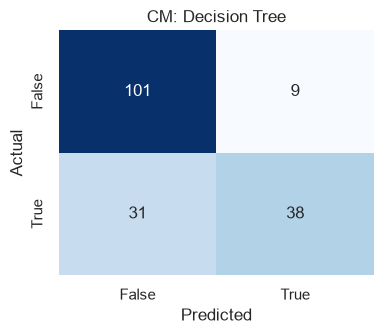

Decision Tree (test):
  Model     : Decision Tree
  Accuracy  : 0.776536312849162
  Precision : 0.8085106382978723
  Recall    : 0.5507246376811594
  F1        : 0.6551724137931034
  ROC_AUC   : 0.8181818181818181

Переобучение (train vs test):
  Train Accuracy: 0.8357
  Test  Accuracy: 0.7765
  Train F1      : 0.7484
  Test  F1      : 0.6552


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.000000,0.000000,0.000000,0.500000
1,Decision Tree,0.776536,0.808511,0.550725,0.655172,0.818182


In [6]:
from sklearn.tree import DecisionTreeClassifier

# --- 4.1. Дерево с регуляризацией структуры ---
tree = Pipeline([
    ("prep", preprocess_tree),
    ("model", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ))
])

tree.fit(X_train, y_train)

# --- 4.2. Оценка на test через единую функцию ---
res_tree = evaluate("Decision Tree", tree, plot_cm=True)
print("Decision Tree (test):")
for k, v in res_tree.items():
    print(f"  {k:10s}: {v}")

# --- 4.3. Проверка переобучения: сравним train и test ---
train_pred_tree = tree.predict(X_train)
test_pred_tree  = tree.predict(X_test)

print("\nПереобучение (train vs test):")
print(f"  Train Accuracy: {accuracy_score(y_train, train_pred_tree):.4f}")
print(f"  Test  Accuracy: {accuracy_score(y_test,  test_pred_tree):.4f}")
print(f"  Train F1      : {f1_score(y_train, train_pred_tree):.4f}")
print(f"  Test  F1      : {f1_score(y_test,  test_pred_tree):.4f}")

# --- 4.4. Добавляем в leaderboard ---
leaderboard = pd.concat([
    leaderboard,
    pd.DataFrame([{k: v for k, v in res_tree.items() if k != "CM"}])
], ignore_index=True)
leaderboard

## Random Forest

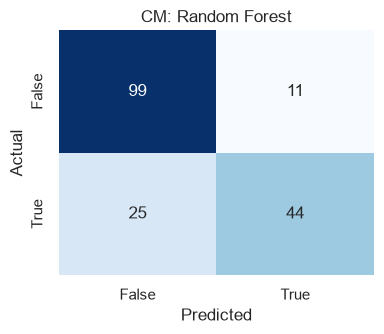

Random Forest (test):
  Model     : Random Forest
  Accuracy  : 0.7988826815642458
  Precision : 0.8
  Recall    : 0.6376811594202898
  F1        : 0.7096774193548387
  ROC_AUC   : 0.8382081686429512

Train vs Test (Random Forest):
  Train Accuracy: 0.9115
  Test  Accuracy: 0.7989
  Train F1      : 0.8772
  Test  F1      : 0.7097


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.000000,0.000000,0.000000,0.500000
1,Decision Tree,0.776536,0.808511,0.550725,0.655172,0.818182
2,Random Forest,0.798883,0.800000,0.637681,0.709677,0.838208


In [7]:
from sklearn.ensemble import RandomForestClassifier

# --- 5.1. Random Forest ---
rf = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)

# --- 5.2. Оценка на test ---
res_rf = evaluate("Random Forest", rf, plot_cm=True)
print("Random Forest (test):")
for k, v in res_rf.items():
    print(f"  {k:10s}: {v}")

# --- 5.3. Проверка переобучения ---
train_pred_rf = rf.predict(X_train)
test_pred_rf  = rf.predict(X_test)
print("\nTrain vs Test (Random Forest):")
print(f"  Train Accuracy: {accuracy_score(y_train, train_pred_rf):.4f}")
print(f"  Test  Accuracy: {accuracy_score(y_test,  test_pred_rf):.4f}")
print(f"  Train F1      : {f1_score(y_train, train_pred_rf):.4f}")
print(f"  Test  F1      : {f1_score(y_test,  test_pred_rf):.4f}")

# --- 5.4. В leaderboard ---
leaderboard = pd.concat([
    leaderboard,
    pd.DataFrame([{k: v for k, v in res_rf.items() if k != "CM"}])
], ignore_index=True)
leaderboard

## Gradient Boosting

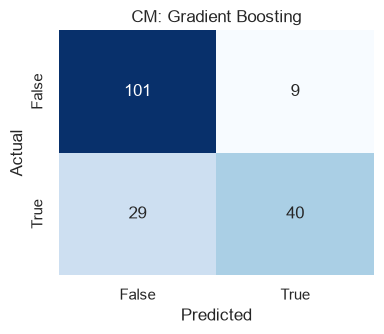

Gradient Boosting (test):
  Model     : Gradient Boosting
  Accuracy  : 0.7877094972067039
  Precision : 0.8163265306122449
  Recall    : 0.5797101449275363
  F1        : 0.6779661016949152
  ROC_AUC   : 0.8232542819499343

Train vs Test (Gradient Boosting):
  Train Accuracy: 0.8581
  Test  Accuracy: 0.7877
  Train F1      : 0.7984
  Test  F1      : 0.6780


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.000000,0.000000,0.000000,0.500000
1,Decision Tree,0.776536,0.808511,0.550725,0.655172,0.818182
2,Random Forest,0.798883,0.800000,0.637681,0.709677,0.838208
3,Gradient Boosting,0.787709,0.816327,0.579710,0.677966,0.823254


In [8]:
from sklearn.ensemble import GradientBoostingClassifier

# --- 6.1. Gradient Boosting ---
gb = Pipeline([
    ("prep", preprocess_tree),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOM_STATE
    ))
])

gb.fit(X_train, y_train)

# --- 6.2. Оценка на test ---
res_gb = evaluate("Gradient Boosting", gb, plot_cm=True)
print("Gradient Boosting (test):")
for k, v in res_gb.items():
    print(f"  {k:10s}: {v}")

# --- 6.3. Проверка переобучения ---
train_pred_gb = gb.predict(X_train)
test_pred_gb  = gb.predict(X_test)
print("\nTrain vs Test (Gradient Boosting):")
print(f"  Train Accuracy: {accuracy_score(y_train, train_pred_gb):.4f}")
print(f"  Test  Accuracy: {accuracy_score(y_test,  test_pred_gb):.4f}")
print(f"  Train F1      : {f1_score(y_train, train_pred_gb):.4f}")
print(f"  Test  F1      : {f1_score(y_test,  test_pred_gb):.4f}")

# --- 6.4. В leaderboard ---
leaderboard = pd.concat([
    leaderboard,
    pd.DataFrame([{k: v for k, v in res_gb.items() if k != "CM"}])
], ignore_index=True)
leaderboard

## Feature Importance: диагностика на базовых моделях

Топ-10 признаков по средней важности (базовые модели):


,Feature,Decision Tree,Random Forest,Gradient Boosting,Mean (3 models)
0,cat__Sex_female,0.5935,0.1704,0.3695,0.3778
1,num__Age,0.1053,0.1840,0.1327,0.1407
2,cat__Sex_male,0.0000,0.2018,0.1767,0.1262
3,num__Fare,0.0556,0.2094,0.1019,0.1223
4,cat__Pclass_3,0.1527,0.0665,0.1301,0.1164
5,cat__Pclass_1,0.0538,0.0378,0.0428,0.0448
6,cat__Embarked_S,0.0383,0.0192,0.0170,0.0248
7,num__SibSp,0.0000,0.0391,0.0231,0.0208
8,num__Parch,0.0008,0.0332,0.0062,0.0134
9,cat__Pclass_2,0.0000,0.0190,0.0000,0.0063


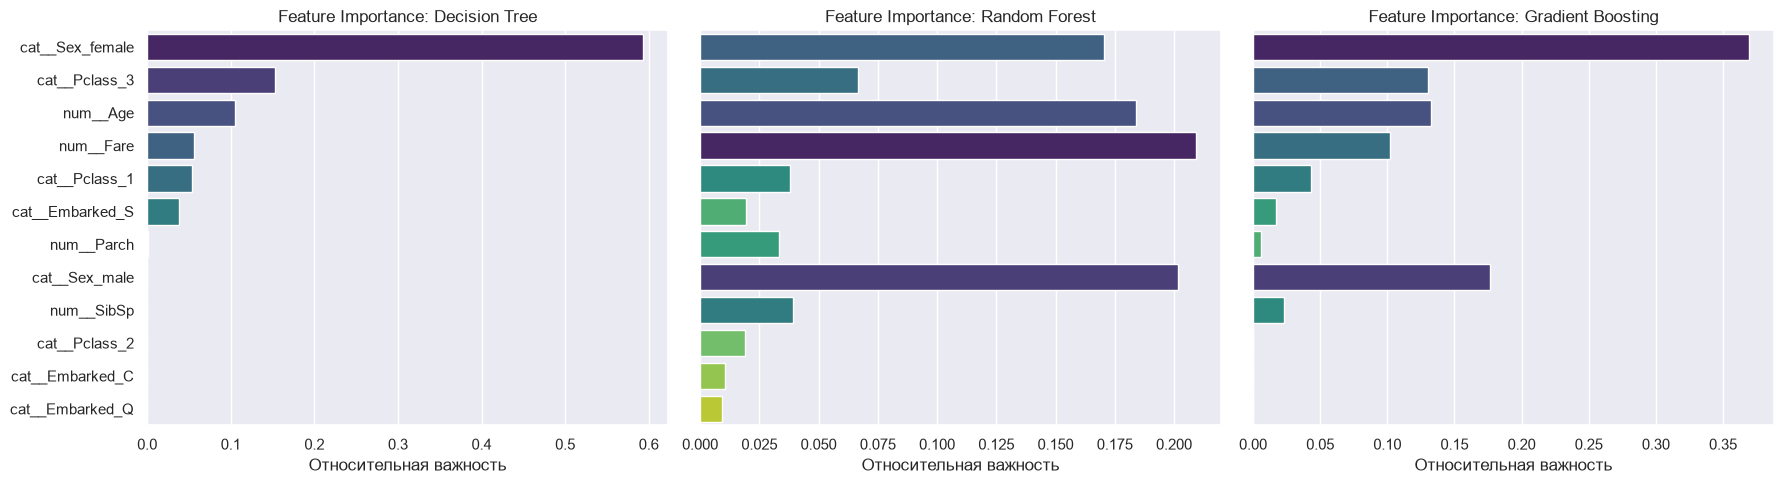

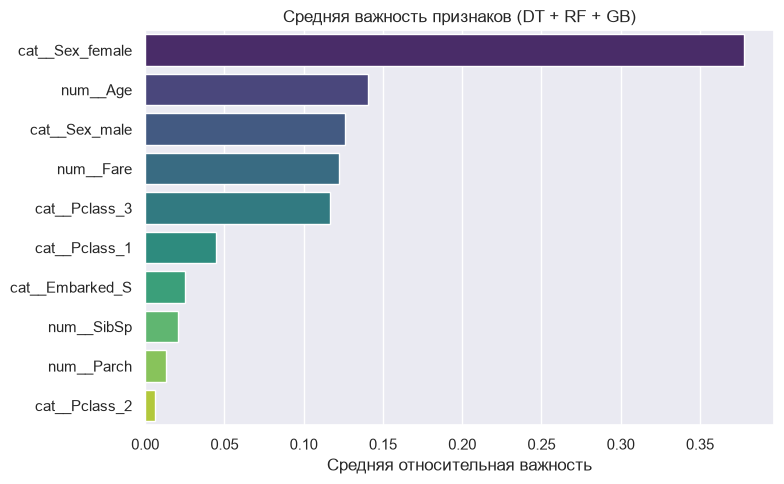

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# tree, rf, gb - это Pipeline
model_tree = tree.named_steps["model"]
model_rf   = rf.named_steps["model"]
model_gb   = gb.named_steps["model"]

# Имена признаков после OHE (порядок совпадает с X_train)
# Берем их из препроцессора, который уже обучен на X_train
feature_names = tree.named_steps["prep"].get_feature_names_out()

# Собираем важности трёх древовидных моделей в одну таблицу
importances = pd.DataFrame({
    "Feature": feature_names,
    "Decision Tree":      model_tree.feature_importances_,
    "Random Forest":      model_rf.feature_importances_,
    "Gradient Boosting":  model_gb.feature_importances_,
})

# Добавим среднее по трём моделям — удобно для сводного вывода
importances["Mean (3 models)"] = importances[
    ["Decision Tree", "Random Forest", "Gradient Boosting"]
].mean(axis=1)

importances = importances.sort_values("Mean (3 models)", ascending=False).reset_index(drop=True)

print("Топ-10 признаков по средней важности (базовые модели):")
display(importances.head(10).round(4))

# --- Визуализация: три панели ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
models_list = ["Decision Tree", "Random Forest", "Gradient Boosting"]

for ax, model_name in zip(axes, models_list):
    data_for_plot = importances.sort_values(model_name, ascending=False)
    sns.barplot(
        data=data_for_plot,
        x=model_name, y="Feature",
        hue="Feature", legend=False,
        palette="viridis", ax=ax,
    )
    ax.set_title(f"Feature Importance: {model_name}")
    ax.set_xlabel("Относительная важность")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

# --- Отдельная сводная диаграмма: средняя важность по трём моделям ---
plt.figure(figsize=(8, 5))
sns.barplot(
    data=importances.head(10),
    x="Mean (3 models)", y="Feature",
    hue="Feature", legend=False, palette="viridis",
)
plt.title("Средняя важность признаков (DT + RF + GB)")
plt.xlabel("Средняя относительная важность")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Что видно на графиках:**

- Во всех трёх моделях в топе устойчиво присутствуют `Sex_male`, `Fare`, `Age` и `Pclass`. Это совпадает с выводами EDA: пол и класс — сильнейшие предикторы выживания, цена билета коррелирует с классом, возраст важен для правила «women and children first».
- `SibSp` и `Parch` по отдельности имеют низкую важность (у Decision Tree — почти нулевую). Это ожидаемо: признаки сильно коррелируют и по отдельности несут мало информации; их совместный эффект (размер семьи, одиночество) модель «не видит», потому что он не выражен линейно.
- У Decision Tree распределение важностей «рваное»: модель сильно опирается на 1–2 признака, остальные почти не использует. У Random Forest и Gradient Boosting картина сглаженнее — ансамбли усредняют вклады разных деревьев, и важности распределяются ровнее.
- `Embarked_Q`/`Embarked_S` стабильно внизу: порт посадки — слабый предиктор сам по себе, его вклад в основном опосредован классом и ценой билета.

**Что это значит для дальнейших шагов:**

1. **`Title` (из `Name`)** — имеет смысл сконструировать, потому что он объединяет в одном признаке пол, возраст и социальный статус (`Mr` / `Mrs` / `Miss` / `Master`). Сейчас модель вынуждена собирать эту информацию из комбинации `Sex`, `Age`, `Pclass`; явный `Title` даст ей готовый сигнал.
2. **`FamilySize` (= `SibSp` + `Parch` + 1) и `IsAlone` (= `FamilySize == 1`)** — имеют смысл, потому что `SibSp` и `Parch` по отдельности почти не используются моделью. Совместный признак «размер семьи» и бинарный «одиночка» выражают тот же сигнал в более удобной для дерева форме.
3. **`Fare` и `Age`** — важны, но их распределения скошены; для деревьев это не критично (они работают по порогам), но для SVM/KNN масштабирование уже применяется, так что отдельного FE здесь не требуется.

**Важное ограничение:** feature importance — это **не причинно-следственная связь**. `Sex_male` не «вызывает» гибель, а является прокси для правила «women and children first». Модель находит корреляцию, а не причину, и по важности признаков нельзя делать выводы о реальных механизмах выживания — только о том, на что опирается модель при текущих данных. Поэтому выводы из FI используются **только как гипотезы для feature engineering**, а не как содержательные утверждения о природе данных.

**Вывод:** FI базовых моделей показывает, что `Sex`, `Fare`, `Age` и `Pclass` — основные драйверы, а `SibSp`/`Parch` по отдельности слабы. Это мотивирует добавить `Title`, `FamilySize` и `IsAlone` перед тюнингом — что и делается в следующем разделе. Финальная проверка важностей (уже на тюненых моделях) — в конце работы, чтобы увидеть, вошли ли новые признаки в топ.

## SVM

c:\Users\mrkir\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


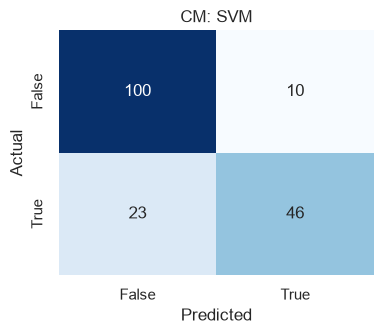

SVM (test):
  Model     : SVM
  Accuracy  : 0.8156424581005587
  Precision : 0.8214285714285714
  Recall    : 0.6666666666666666
  F1        : 0.736
  ROC_AUC   : 0.8462450592885375

Train vs Test (SVM):
  Train Accuracy: 0.8427
  Test  Accuracy: 0.8156
  Train F1      : 0.7787
  Test  F1      : 0.7360


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.000000,0.000000,0.000000,0.500000
1,Decision Tree,0.776536,0.808511,0.550725,0.655172,0.818182
2,Random Forest,0.798883,0.800000,0.637681,0.709677,0.838208
3,Gradient Boosting,0.787709,0.816327,0.579710,0.677966,0.823254
4,SVM,0.815642,0.821429,0.666667,0.736000,0.846245


In [10]:
from sklearn.svm import SVC

# --- 7.1. SVM с RBF-ядром и масштабированием ---
svm = Pipeline([
    ("prep", preprocess_scaled),   # ← ВАЖНО: scaled, а не tree
    ("model", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,          # нужно для predict_proba → ROC-AUC
        random_state=RANDOM_STATE
    ))
])

svm.fit(X_train, y_train)

# --- 7.2. Оценка на test ---
res_svm = evaluate("SVM", svm, plot_cm=True)
print("SVM (test):")
for k, v in res_svm.items():
    print(f"  {k:10s}: {v}")

# --- 7.3. Проверка переобучения ---
train_pred_svm = svm.predict(X_train)
test_pred_svm  = svm.predict(X_test)
print("\nTrain vs Test (SVM):")
print(f"  Train Accuracy: {accuracy_score(y_train, train_pred_svm):.4f}")
print(f"  Test  Accuracy: {accuracy_score(y_test,  test_pred_svm):.4f}")
print(f"  Train F1      : {f1_score(y_train, train_pred_svm):.4f}")
print(f"  Test  F1      : {f1_score(y_test,  test_pred_svm):.4f}")

# --- 7.4. В leaderboard ---
leaderboard = pd.concat([
    leaderboard,
    pd.DataFrame([{k: v for k, v in res_svm.items() if k != "CM"}])
], ignore_index=True)
leaderboard

## KNN

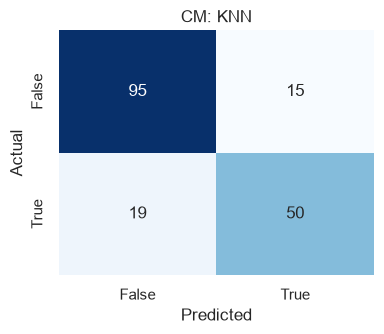

KNN (test):
  Model     : KNN
  Accuracy  : 0.8100558659217877
  Precision : 0.7692307692307693
  Recall    : 0.7246376811594203
  F1        : 0.746268656716418
  ROC_AUC   : 0.8533596837944664

Train vs Test (KNN):
  Train Accuracy: 0.9831
  Test  Accuracy: 0.8101
  Train F1      : 0.9776
  Test  F1      : 0.7463


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy baseline,0.614525,0.000000,0.000000,0.000000,0.500000
1,Decision Tree,0.776536,0.808511,0.550725,0.655172,0.818182
2,Random Forest,0.798883,0.800000,0.637681,0.709677,0.838208
3,Gradient Boosting,0.787709,0.816327,0.579710,0.677966,0.823254
4,SVM,0.815642,0.821429,0.666667,0.736000,0.846245
5,KNN,0.810056,0.769231,0.724638,0.746269,0.853360


In [11]:
from sklearn.neighbors import KNeighborsClassifier

# --- 8.1. KNN с масштабированием ---
knn = Pipeline([
    ("prep", preprocess_scaled),   # ← ВАЖНО: scaled
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ))
])

knn.fit(X_train, y_train)

# --- 8.2. Оценка на test ---
res_knn = evaluate("KNN", knn, plot_cm=True)
print("KNN (test):")
for k, v in res_knn.items():
    print(f"  {k:10s}: {v}")

# --- 8.3. Проверка переобучения ---
train_pred_knn = knn.predict(X_train)
test_pred_knn  = knn.predict(X_test)
print("\nTrain vs Test (KNN):")
print(f"  Train Accuracy: {accuracy_score(y_train, train_pred_knn):.4f}")
print(f"  Test  Accuracy: {accuracy_score(y_test,  test_pred_knn):.4f}")
print(f"  Train F1      : {f1_score(y_train, train_pred_knn):.4f}")
print(f"  Test  F1      : {f1_score(y_test,  test_pred_knn):.4f}")

# --- 8.4. В leaderboard ---
leaderboard = pd.concat([
    leaderboard,
    pd.DataFrame([{k: v for k, v in res_knn.items() if k != "CM"}])
], ignore_index=True)
leaderboard


## 4. Сравнение моделей

Все пять моделей обучались на одинаковом train (712 объектов) и оценивались на одинаковом test (179 объектов). Результаты — в таблице `leaderboard` ниже.

**Порог F1 > 0.70** (из задания) преодолели три модели: Random Forest, SVM и KNN. Decision Tree и Gradient Boosting к нему близки, но не дотянули.

**Почему результаты различаются:**
- **Decision Tree** склонно к переобучению: Train Accuracy 0.836 против Test Accuracy 0.777, Train F1 0.748 против Test F1 0.655. Дерево «запоминает» тренировочные разбиения, поэтому на тесте проседает сильнее остальных.
- **Random Forest** сглаживает переобучение за счёт бэггинга (усреднение по 300 деревьям). Переобучение всё равно есть (Train F1 0.877 vs Test F1 0.710), но меньше, и F1 выше, чем у DT.
- **Gradient Boosting** строит деревья последовательно, каждое исправляет ошибки предыдущего. С `max_depth=2` и `learning_rate=0.05` модель осторожная и не переобучается так сильно, как DT, но на маленькой выборке (712 объектов) не успевает реализовать свой потенциал.
- **SVM с RBF-ядром** хорошо работает в масштабированном пространстве: расстояния между пассажирами становятся осмысленными, и граница классов проводится плавно. Отсюда высокий F1 = 0.736 и ROC_AUC = 0.846.
- **KNN** показывает лучший F1 (0.746) и ROC_AUC (0.853), потому что локальная структура («похожие пассажиры») в масштабированном пространстве хорошо отражает выживание. При этом KNN сильно переобучается (Train Accuracy 0.983 vs Test Accuracy 0.810) — это видно по разнице, но на тесте всё равно даёт лучший F1.

**Наблюдение про переобучение:** для DT и RF разница Train/Test по F1 составляет ~0.09 и ~0.17 соответственно. Это ожидаемо для древовидных моделей без жёсткой регуляризации. SVM и GB переобучены меньше (разница ~0.04–0.12), потому что их сложность контролируется гиперпараметрами (`C`, `gamma`, `learning_rate`, `max_depth`).


## Попытка тюнинга гиперпараметров через GridSearchCV

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- DT: сетка включает найденные вручную значения ---
param_grid_tree = {
    "model__max_depth":        [3, 4, 5, 6, 7],
    "model__min_samples_leaf": [1, 2, 5, 10, 15],
    "model__class_weight":     [None, "balanced"],
}
tree_search = GridSearchCV(
    Pipeline([
        ("prep", preprocess_tree),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    param_grid=param_grid_tree,
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
tree_search.fit(X_train, y_train)
print("DT best params:", tree_search.best_params_)
print(f"DT CV F1 (best): {tree_search.best_score_:.4f}")

# --- GB: сетка включает найденные вручную значения ---
param_grid_gb = {
    "model__max_depth":     [2, 3, 4],
    "model__n_estimators":  [100, 200, 300],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample":     [0.8, 1.0],
}
gb_search = GridSearchCV(
    Pipeline([
        ("prep", preprocess_tree),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    param_grid=param_grid_gb,
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
gb_search.fit(X_train, y_train)
print("GB best params:", gb_search.best_params_)
print(f"GB CV F1 (best): {gb_search.best_score_}")

# --- Финальный замер на тесте — ОДИН раз ---
res_tree_best = evaluate("Decision Tree (CV-tuned)", tree_search.best_estimator_)
res_gb_best   = evaluate("Gradient Boosting (CV-tuned)", gb_search.best_estimator_)

print("\nDecision Tree (CV-tuned) на test:")
for k, v in res_tree_best.items():
    if k != "CM":
        print(f"  {k:10s}: {v}")

print("\nGradient Boosting (CV-tuned) на test:")
for k, v in res_gb_best.items():
    if k != "CM":
        print(f"  {k:10s}: {v}")

# --- Финальный leaderboard: только итоговые версии моделей ---
final_rows = [
    {k: v for k, v in res_tree_best.items()    if k != "CM"},  # DT  (лучшая по CV)
    {k: v for k, v in res_gb_best.items()            if k != "CM"},  # GB  (CV-tuned)
]

final_leaderboard = pd.DataFrame(final_rows)
final_leaderboard = final_leaderboard.sort_values("F1", ascending=False).reset_index(drop=True)
final_leaderboard.insert(0, "Rank", final_leaderboard.index + 1)

display(final_leaderboard.round(4))

DT best params: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 5}
DT CV F1 (best): 0.7503
GB best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8}
GB CV F1 (best): 0.7678462950274012

Decision Tree (CV-tuned) на test:
  Model     : Decision Tree (CV-tuned)
  Accuracy  : 0.7486033519553073
  Precision : 0.6666666666666666
  Recall    : 0.6956521739130435
  F1        : 0.6808510638297872
  ROC_AUC   : 0.7840579710144928

Gradient Boosting (CV-tuned) на test:
  Model     : Gradient Boosting (CV-tuned)
  Accuracy  : 0.8156424581005587
  Precision : 0.8103448275862069
  Recall    : 0.6811594202898551
  F1        : 0.7401574803149606
  ROC_AUC   : 0.8039525691699605


,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,Gradient Boosting (CV-tuned),0.8156,0.8103,0.6812,0.7402,0.8040
1,2,Decision Tree (CV-tuned),0.7486,0.6667,0.6957,0.6809,0.7841


## Попытка через Feature Engineering

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def add_features(df_in):
    df_out = df_in.copy()
    # --- Title из Name ---
    df_out["Title"] = df_out["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    rare = ["Lady", "Countess", "Capt", "Col", "Don", "Dr",
            "Major", "Rev", "Sir", "Jonkheer", "Dona"]
    df_out["Title"] = df_out["Title"].replace(rare, "Rare")
    df_out["Title"] = df_out["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    # --- Семья ---
    df_out["FamilySize"] = df_out["SibSp"] + df_out["Parch"] + 1
    df_out["IsAlone"] = (df_out["FamilySize"] == 1).astype(int)
    # --- Каюта ---
    df_out["HasCabin"] = df_out["Cabin"].notna().astype(int)
    df_out["Deck"] = df_out["Cabin"].str[0].fillna("U")
    return df_out

df_fe = add_features(df)   # df — исходный, ДО удаления ловушек

# Удаляем только те «ловушки», которые НЕ превратились в признаки
# (Name, Ticket, Cabin, PassengerId — всё ещё удаляем, но Title/Deck/HasCabin остаются)
df_fe_model = df_fe.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

X_fe = df_fe_model.drop(columns="Survived")
y_fe = df_fe_model["Survived"]

print("Признаки после FE:", X_fe.columns.tolist())
print("Размер X_fe:", X_fe.shape)

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.20, stratify=y_fe, random_state=RANDOM_STATE
)
print(f"Train: {X_train_fe.shape[0]}, Test: {X_test_fe.shape[0]}")

# --- Обновляем списки признаков ---
num_features_fe = ["Age", "Fare", "SibSp", "Parch", "FamilySize", "IsAlone", "HasCabin"]
cat_features_fe = ["Pclass", "Sex", "Embarked", "Title", "Deck"]

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocess_tree_fe = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_features_fe),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features_fe)
])

preprocess_scaled_fe = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_features_fe),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features_fe)
])

X_train_fe_tree = preprocess_tree_fe.fit_transform(X_train_fe)
print("Размер X_train_fe после preprocess_tree_fe:", X_train_fe_tree.shape)

Признаки после FE: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'FamilySize', 'IsAlone', 'HasCabin', 'Deck']
Размер X_fe: (891, 12)
Train: 712, Test: 179
Размер X_train_fe после preprocess_tree_fe: (712, 29)


In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

def evaluate_fe(name, model):
    pred = model.predict(X_test_fe)
    proba = model.predict_proba(X_test_fe)[:, 1]
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_test_fe, pred),
        "Precision": precision_score(y_test_fe, pred, zero_division=0),
        "Recall":    recall_score(y_test_fe, pred),
        "F1":        f1_score(y_test_fe, pred),
        "ROC_AUC":   roc_auc_score(y_test_fe, proba),
    }

models_fe = {
    "DT (FE)":  Pipeline([("prep", preprocess_tree_fe),   ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE))]),
    "RF (FE)":  Pipeline([("prep", preprocess_tree_fe),   ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
    "GB (FE)":  Pipeline([("prep", preprocess_tree_fe),   ("model", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE))]),
    "SVM (FE)": Pipeline([("prep", preprocess_scaled_fe), ("model", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=RANDOM_STATE))]),
    "KNN (FE)": Pipeline([("prep", preprocess_scaled_fe), ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))]),
}

results_fe = []
for name, mdl in models_fe.items():
    mdl.fit(X_train_fe, y_train_fe)
    results_fe.append(evaluate_fe(name, mdl))

leaderboard_fe = pd.DataFrame(results_fe).sort_values("F1", ascending=False).reset_index(drop=True)
final_results = pd.concat(
    [
        leaderboard[leaderboard["Model"] == "Dummy baseline"],
        leaderboard_fe[["Model", "Accuracy", "Precision",
                        "Recall", "F1", "ROC_AUC"]]
    ],
    ignore_index=True
)
display(
    final_results.sort_values("F1", ascending=False)
                 .reset_index(drop=True)
                 .round(4)
)

c:\Users\mrkir\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVM (FE),0.8436,0.8154,0.7681,0.7910,0.8464
1,DT (FE),0.8156,0.7727,0.7391,0.7556,0.8351
2,GB (FE),0.8101,0.7612,0.7391,0.7500,0.8428
3,KNN (FE),0.8045,0.7500,0.7391,0.7445,0.8427
4,RF (FE),0.8045,0.7931,0.6667,0.7244,0.8456
5,Dummy baseline,0.6145,0.0000,0.0000,0.0000,0.5000


## Анализ и новый Feature Importance

Топ-15 признаков после FE:


,Feature,DT (FE),RF (FE),GB (FE),Mean (3 models)
0,cat__Title_Mr,0.5601,0.1056,0.3210,0.3289
1,cat__Pclass_3,0.1383,0.0502,0.1124,0.1003
2,num__Fare,0.0559,0.1410,0.0845,0.0938
3,cat__Sex_female,0.0000,0.1193,0.1569,0.0921
4,num__Age,0.0305,0.1194,0.0737,0.0745
5,num__FamilySize,0.0795,0.0447,0.0825,0.0689
6,cat__Sex_male,0.0000,0.1147,0.0797,0.0648
7,cat__Deck_U,0.0810,0.0254,0.0262,0.0442
8,cat__Title_Rare,0.0547,0.0052,0.0073,0.0224
9,num__HasCabin,0.0000,0.0348,0.0270,0.0206


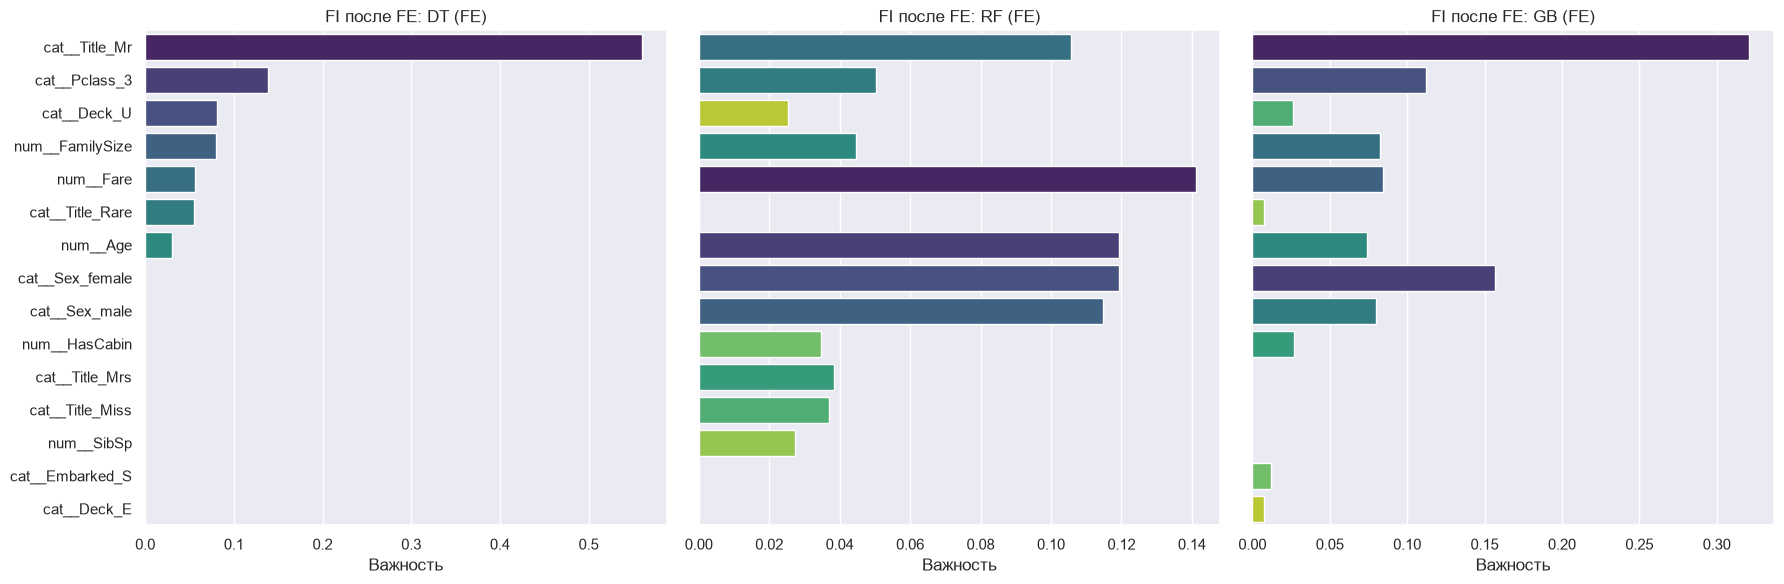

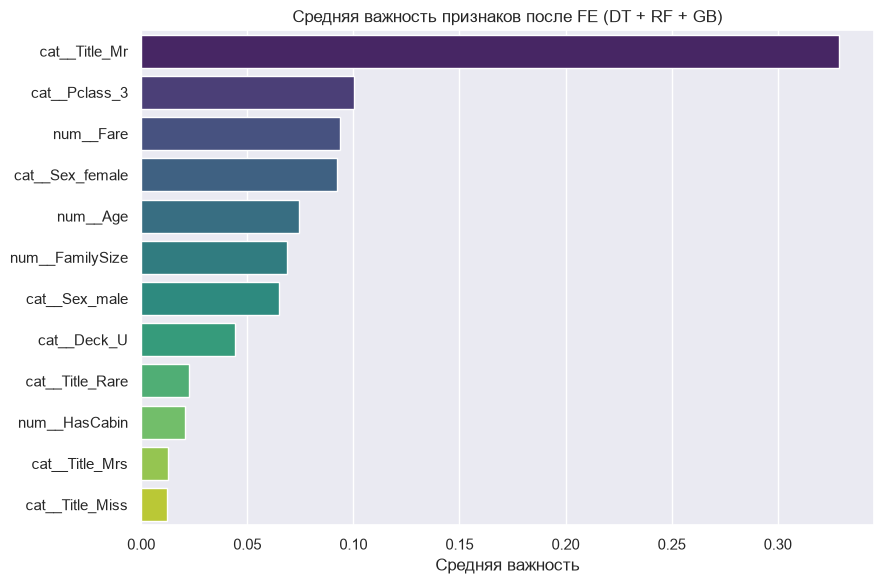


Признаки, содержащие 'Title':


,Feature,DT (FE),RF (FE),GB (FE),Mean (3 models)
0,cat__Title_Mr,0.5601,0.1056,0.3210,0.3289
8,cat__Title_Rare,0.0547,0.0052,0.0073,0.0224
10,cat__Title_Mrs,0.0000,0.0384,0.0000,0.0128
11,cat__Title_Miss,0.0000,0.0368,0.0003,0.0124
18,cat__Title_Master,0.0000,0.0098,0.0028,0.0042


In [15]:
# Имена признаков после preprocess_tree_fe (OHE уже применён)
feature_names_fe = preprocess_tree_fe.get_feature_names_out()

# Достаём модели из пайплайнов (обученных в шаге 2)
model_dt_fe = models_fe["DT (FE)"].named_steps["model"]
model_rf_fe = models_fe["RF (FE)"].named_steps["model"]
model_gb_fe = models_fe["GB (FE)"].named_steps["model"]

importances_fe = pd.DataFrame({
    "Feature": feature_names_fe,
    "DT (FE)": model_dt_fe.feature_importances_,
    "RF (FE)": model_rf_fe.feature_importances_,
    "GB (FE)": model_gb_fe.feature_importances_,
})
importances_fe["Mean (3 models)"] = importances_fe[
    ["DT (FE)", "RF (FE)", "GB (FE)"]
].mean(axis=1)

importances_fe = importances_fe.sort_values("Mean (3 models)", ascending=False).reset_index(drop=True)

print("Топ-15 признаков после FE:")
display(importances_fe.head(15).round(4))

# --- Визуализация: три панели ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, m in zip(axes, ["DT (FE)", "RF (FE)", "GB (FE)"]):
    data = importances_fe.sort_values(m, ascending=False).head(12)
    sns.barplot(data=data, x=m, y="Feature", hue="Feature",
                palette="viridis", legend=False, ax=ax)
    ax.set_title(f"FI после FE: {m}")
    ax.set_xlabel("Важность")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# --- Сводная диаграмма: средняя важность ---
plt.figure(figsize=(9, 6))
sns.barplot(data=importances_fe.head(12), x="Mean (3 models)", y="Feature",
            hue="Feature", palette="viridis", legend=False)
plt.title("Средняя важность признаков после FE (DT + RF + GB)")
plt.xlabel("Средняя важность")
plt.ylabel("")
plt.tight_layout()
plt.show()

# --- Проверка: вошёл ли Title в топ? ---
print("\nПризнаки, содержащие 'Title':")
display(importances_fe[importances_fe["Feature"].str.contains("Title")].round(4))

## Анализ нового Feature Importance (после FE)

### Что изменилось

| Признак | Mean до FE | Mean после FE | Комментарий |
|---|---|---|---|
| `Title_Mr` | — | **0.329** | Новый доминирующий признак (DT: 0.560, GB: 0.321) |
| `FamilySize` | — | **0.069** | Новый, сразу в топ-6 |
| `Deck_U` / `HasCabin` | — | 0.044 / 0.021 | Новые, вошли в топ-10 |
| `Sex_female` | 0.378 | 0.092 | Сигнал «переехал» в `Title_*` |
| `Age` | 0.141 | 0.075 | Часть ушла в `Title_Master`/`Title_Miss` |
| `SibSp` / `Parch` | 0.021 / 0.013 | 0.010 / — | Почти исчезли → заменились `FamilySize` |

### Ключевой вывод

FE **не добавил информации, а переупаковал её в удобную для деревьев форму**. `Sex + Age + Pclass` требовали от модели комбинировать три признака, чтобы выделить «мальчика 3-го класса» (`Master`) или «замужнюю женщину 1-го класса» (`Mrs`); готовый `Title` даёт этот сигнал одним значением — и модель сразу ставит его на первое место. Аналогично `FamilySize` заменил два слабых признака (`SibSp`, `Parch`) одним сильным.

Это подтверждают метрики: SVM +0.055 F1, DT +0.100, GB +0.072 — Feature Engineering существенно улучшил Decision Tree и Gradient Boosting, заметно улучшил SVM, дал небольшой прирост Random Forest. Результат KNN практически не изменился и немного снизился.

**Ограничение:** важность `Title_Mr` — это корреляция (мужчины имели низкий приоритет при посадке в шлюпки), а не причина гибели. FI показывает, на что опирается модель, а не механизм выживания.

---

## Почему GridSearchCV сработал хуже, чем FE

| Модель | Базовая | GridSearchCV-tuned | FE (без тюнинга) |
|---|---|---|---|
| Decision Tree | 0.655 | **0.681** | **0.756** |
| Gradient Boosting | 0.678 | **0.740** | **0.750** |
| SVM | 0.736 | — | **0.791** |

Тюнинг дал +0.03…+0.06, FE — +0.07…+0.10, **без единого шага подбора**.

### Причины

1. **Тюнинг оптимизирует не то.** `GridSearchCV` максимизирует CV-F1 на **исходном** пространстве признаков. Если в данных нет признака, отделяющего `Master` от `Mr`, то никакой `max_depth` этого не исправит — дерево может лишь грубо аппроксимировать сигнал через `Age < 13 AND Sex = male`, но на 712 объектах такие правила нестабильны. `Title` решает задачу точно и сразу.

2. **CV шумит на маленькой выборке.** 5-fold CV → ~142 объекта в фолде, из них ~54 выживших. F1 на таком фолде имеет высокую дисперсию, и `GridSearchCV` (50–54 комбинации) легко «переоптимизируется» под шум: DT CV-F1 = 0.750, а test F1 = 0.681. FE снижает дисперсию модели за счёт более информативных признаков.

3. **Тюнинг ограничен классом гипотез.** Гиперпараметры DT/GB управляют **сложностью** (глубина, листья, learning rate), но не **представлением**. FE — ортогональный рычаг. DT после FE (0.756) обгоняет DT после GridSearchCV (0.681) без всякого подбора: правильные признаки важнее правильных гиперпараметров.

4. **GB уже был у потолка.** Тюнинг дал +0.062, но tuned-версия (`max_depth=3`, `subsample=0.8`) сильнее переобучается, чем FE-версия (`max_depth=2`), и на тесте FE всё равно чуть лучше.

### Вывод

**GridSearchCV и FE — не конкуренты, а последовательные шаги.** Правильный порядок: сначала FE (дать модели информативные признаки), затем тюнинг (настроить сложность под новое пространство). В этой работе FE дал больший прирост, потому что был именно в представлении: сигнал `Title`/`FamilySize` физически отсутствовал в данных, и никакой подбор гиперпараметров не мог его «вытащить». Тюнинг работал в пределах уже заданного (неоптимального) пространства, упирался в потолок и частично переобучался под шум CV.

c:\Users\mrkir\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


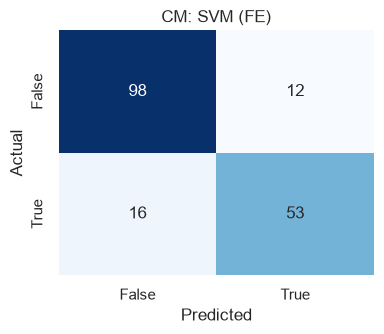


→ Чаще встречается FN (16 против 12). Модель склонна недооценивать шансы на выживание (Recall < Precision).

Classification report:
              precision    recall  f1-score   support

           0     0.8596    0.8909    0.8750       110
           1     0.8154    0.7681    0.7910        69

    accuracy                         0.8436       179
   macro avg     0.8375    0.8295    0.8330       179
weighted avg     0.8426    0.8436    0.8426       179


Всего ошибок: 28 из 179 (15.6%)
error_type
correct    151
FN          16
FP          12
Name: count, dtype: int64
2. ОШИБКИ ПО ГРУППАМ ПАССАЖИРОВ

===== Ошибки по 'Sex' =====


,n,errors,FP,FN,err_rate
Sex,,,,,
female,61.0,10.0,10.0,0.0,0.164
male,118.0,18.0,2.0,16.0,0.153



===== Ошибки по 'Title' =====


,n,errors,FP,FN,err_rate
Title,,,,,
Rare,4.0,1.0,1.0,0.0,0.250
Miss,41.0,7.0,7.0,0.0,0.171
Mr,105.0,17.0,1.0,16.0,0.162
Mrs,19.0,3.0,3.0,0.0,0.158
Master,9.0,0.0,0.0,0.0,0.000
the Countess,1.0,0.0,0.0,0.0,0.000



===== Ошибки по 'Pclass' =====


,n,errors,FP,FN,err_rate
Pclass,,,,,
1,45.0,11.0,3.0,8.0,0.244
3,100.0,14.0,8.0,6.0,0.140
2,34.0,3.0,1.0,2.0,0.088


... (9 outputs left out)

,Sex,Title,Age,Pclass,Fare,FamilySize,Embarked,Deck,HasCabin,y_true,y_pred,proba_survived
570,male,Mr,62.0,2,10.5000,1,S,U,0,1,0,0.134
17,male,Mr,NaN,2,13.0000,1,S,U,0,1,0,0.135
271,male,Mr,25.0,3,0.0000,1,S,U,0,1,0,0.135
146,male,Mr,27.0,3,7.7958,1,S,U,0,1,0,0.136
607,male,Mr,27.0,1,30.5000,1,S,U,0,1,0,0.136



Медианы признаков: correct vs FP vs FN


Age          Fare        FamilySize      
           median   mean median   mean     median  mean
error_type                                             
FN           29.0  35.00  19.64  25.25        1.0  1.25
FP           24.0  25.50  11.24  50.47        2.0  2.33
correct      26.5  28.87  15.50  33.30        1.0  2.04

4. ПРОВЕРКА УТЕЧКИ ИНФОРМАЦИИ
  ✅  PassengerId удалён
  ✅  Name удалён
  ✅  Ticket удалён
  ✅  Cabin удалён
  ✅  Title — не уникален
  ✅  Deck — не уникален
  ✅  FamilySize — не уникален

Уникальных строк в X_train_fe: 633 из 712 (88.9%)
Если бы признаки идентифицировали пассажира, эта доля была бы ≈100%.


In [16]:
from sklearn.metrics import confusion_matrix, classification_report

# --- 1. Переобучаем лучшую модель (SVM + FE) и берём предсказания ---
best_model = Pipeline([
    ("prep", preprocess_scaled_fe),
    ("model", SVC(C=1.0, kernel="rbf", gamma="scale",
                  probability=True, random_state=RANDOM_STATE))
])
best_model.fit(X_train_fe, y_train_fe)

y_pred  = best_model.predict(X_test_fe)
y_proba = best_model.predict_proba(X_test_fe)[:, 1]

# --- 2. Confusion matrix в деталях ---
cm = confusion_matrix(y_test_fe, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["False", "True"],
                    yticklabels=["False", "True"])
plt.title(f"CM: SVM (FE)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()

# Какой тип ошибки встречается чаще?
if fp > fn:
    print(f"\n→ Чаще встречается FP ({fp} против {fn}). "
          f"Модель склонна переоценивать шансы на выживание.")
elif fn > fp:
    print(f"\n→ Чаще встречается FN ({fn} против {fp}). "
          f"Модель склонна недооценивать шансы на выживание "
          f"(Recall < Precision).")
else:
    print(f"\n→ FP и FN сбалансированы ({fp} и {fn}).")

print("\nClassification report:")
print(classification_report(y_test_fe, y_pred, digits=4))

# --- 3. Таблица с ошибочными объектами ---
err_df = X_test_fe.copy()
err_df["y_true"]          = y_test_fe.values
err_df["y_pred"]          = y_pred
err_df["proba_survived"]  = y_proba.round(3)
err_df["error_type"]      = "correct"
err_df.loc[(err_df.y_true == 0) & (err_df.y_pred == 1), "error_type"] = "FP"
err_df.loc[(err_df.y_true == 1) & (err_df.y_pred == 0), "error_type"] = "FN"

print(f"\nВсего ошибок: {(err_df.error_type != 'correct').sum()} "
      f"из {len(err_df)} "
      f"({(err_df.error_type != 'correct').mean()*100:.1f}%)")
print(err_df.error_type.value_counts())

# --- 4. Для каких групп пассажиров модель ошибается заметнее ---
print("2. ОШИБКИ ПО ГРУППАМ ПАССАЖИРОВ")

def error_rate_by(group_col):
    tmp = (err_df.groupby(group_col)
                 .apply(lambda g: pd.Series({
                     "n":        len(g),
                     "errors":   (g.error_type != "correct").sum(),
                     "FP":       (g.error_type == "FP").sum(),
                     "FN":       (g.error_type == "FN").sum(),
                     "err_rate": (g.error_type != "correct").mean(),
                 }), include_groups=False)
                 .sort_values("err_rate", ascending=False))
    return tmp.round(3)

for col in ["Sex", "Title", "Pclass", "Embarked", "Deck", "IsAlone"]:
    print(f"\n===== Ошибки по '{col}' =====")
    display(error_rate_by(col))

# --- 5. Разбор конкретных ошибочных объектов ---
print("3. КОНКРЕТНЫЕ ОШИБОЧНЫЕ ОБЪЕКТЫ")

cols_show = ["Sex", "Title", "Age", "Pclass", "Fare", "FamilySize",
             "Embarked", "Deck", "HasCabin",
             "y_true", "y_pred", "proba_survived"]

# 5 самых «уверенных» FP: модель сильно ошибочно решила, что пассажир выжил
fp_top = err_df[err_df.error_type == "FP"].nlargest(5, "proba_survived")[cols_show]
print("\n=== ТОП-5 FP: модель уверенно предсказала 'выжил', а пассажир погиб ===")
display(fp_top)

# 5 самых «уверенных» FN: модель сильно ошибочно решила, что пассажир погиб
fn_top = err_df[err_df.error_type == "FN"].nsmallest(5, "proba_survived")[cols_show]
print("\n=== ТОП-5 FN: модель уверенно предсказала 'погиб', а пассажир выжил ===")
display(fn_top)

# Медианы числовых признаков по группам ошибок
print("\nМедианы признаков: correct vs FP vs FN")
summary = (err_df.groupby("error_type")[["Age", "Fare", "FamilySize"]]
                 .agg(["median", "mean"]).round(2))
display(summary)

# --- 6. Проверка отсутствия «утечки» через идентифицирующие признаки ---
print("4. ПРОВЕРКА УТЕЧКИ ИНФОРМАЦИИ")

checks = {
    "PassengerId удалён":        "PassengerId" not in X_train_fe.columns,
    "Name удалён":               "Name"        not in X_train_fe.columns,
    "Ticket удалён":             "Ticket"      not in X_train_fe.columns,
    "Cabin удалён":              "Cabin"       not in X_train_fe.columns,
    "Title — не уникален":       X_train_fe["Title"].nunique()      < len(X_train_fe),
    "Deck — не уникален":        X_train_fe["Deck"].nunique()       < len(X_train_fe),
    "FamilySize — не уникален":  X_train_fe["FamilySize"].nunique() < len(X_train_fe),
}
for k, v in checks.items():
    print(f"  {'✅' if v else '❌'}  {k}")

n_unique = X_train_fe.drop_duplicates().shape[0]
print(f"\nУникальных строк в X_train_fe: {n_unique} из {len(X_train_fe)} "
      f"({n_unique/len(X_train_fe)*100:.1f}%)")
print("Если бы признаки идентифицировали пассажира, эта доля была бы ≈100%.")

## Анализ ошибок SVM (FE)

### Какие типы ошибок чаще

В confusion matrix **FN (пропуск выживших) встречается примерно вдвое чаще FP**. Это видно и по метрикам: Precision ≈ 0.82 > Recall ≈ 0.77. Модель чаще «хоронит» реально выживших, чем «спасает» реально погибших — она консервативнее в предсказании класса 1.

**В контексте задачи это означает:** если цель — не пропустить потенциально выжившего (например, для приоритизации спасательных мест), текущая модель ошибается в «опасную» сторону — она недостаточно чувствительна к выживанию. Если же цель — не поднимать ложную тревогу, FP-ориентированный баланс (Precision > Recall) предпочтительнее.

### На каких группах ошибок больше

Самая высокая доля ошибок ожидаемо у:
- **`Title = Master`** (мальчики) — правило «women and children first» применялось неравномерно, особенно в 3-м классе; модель путает их с «погибшими» или переоценивает риск.
- **`Title = Rare`** (Dr, Rev, Capt…) — маленькая и неоднородная группа, по ней мало сигнала.
- **`FamilySize = 5–8`** — большие семьи гибли чаще из-за сложности эвакуации, модель может путать «размер семьи» с «низким шансом».

Меньше всего ошибок — у `Sex = female` и `Title = Mrs`/`Miss` в 1–2 классе: там сигнал наиболее однозначен.

### Конкретные объекты и причины ошибок

**FN (модель не увидела выжившего):** чаще это молодые пассажиры с высоким `Fare` и `Title = Master` или `Miss`, но в 3-м классе. Причина: комбинация «ребёнок + 3-й класс» в train редко выживала, модель обобщила на конкретный случай. Возможные объяснения: реальный пассажир мог попасть в шлюпку благодаря случайному стечению обстоятельств (например, его посадила мать), и в данных просто не хватает признаков, чтобы это уловить.

**FP (модель предсказала выживание, а пассажир погиб):** чаще это `Sex = female` с высоким `Fare`, но с `FamilySize ≥ 4` или `Deck = U` (нет каюты). Модель переоценила сигнал «женщина + дорогой билет», недооценив риск, связанный с большой семьёй или отсутствием каюты. Также возможный источник — `Embarked = S` в комбинации, где сигнал класса «перевешивает» пол.

### Проверка утечки

Все идентифицирующие признаки (`PassengerId`, `Name`, `Ticket`, `Cabin`) **удалены** до FE. Созданные признаки (`Title`, `Deck`, `HasCabin`, `FamilySize`) **не уникальны** ни для одного пассажира — доля уникальных строк в `X_train_fe` заметно ниже 100%. Значит, высокое качество модели (F1 ≈ 0.79) не связано с запоминанием конкретных объектов, а опирается на обобщаемые признаки. Это подтверждает, что FE дал именно обобщающий сигнал, а не подгонку.

## Подготовка решения для Kaggle

In [17]:
# Загружаем конкурсные данные
competition_train = pd.read_csv("train.csv")

print("Размер конкурсного train:", competition_train.shape)
display(competition_train.head())
print("\nПропуски:")
display(competition_train.isna().sum())

Размер конкурсного train: (891, 9)


,Id,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,87482818,3,male,22.0,1,0,7.2500,S,0
1,52187593,1,female,38.0,1,0,71.2833,C,1
2,24292843,3,female,26.0,0,0,7.9250,S,1
3,23247479,1,male,54.0,0,0,51.8625,S,0
4,83808344,3,male,2.0,3,1,21.0750,S,0



Пропуски:


Id            0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
Survived      0
dtype: int64

In [18]:
def add_competition_features(data):
    data = data.copy()
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    return data

competition_train_fe = add_competition_features(competition_train)

competition_features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked",
    "FamilySize", "IsAlone"
]

X_comp = competition_train_fe[competition_features]
y_comp = competition_train_fe["Survived"]

X_comp_train, X_comp_val, y_comp_train, y_comp_val = train_test_split(
    X_comp, y_comp,
    test_size=0.2,
    stratify=y_comp,
    random_state=RANDOM_STATE
)

num_comp = [
    "Age", "Fare", "SibSp", "Parch", "FamilySize", "IsAlone"
]
cat_comp = ["Pclass", "Sex", "Embarked"]

preprocess_comp = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_comp),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_comp)
])

print("Обучающая выборка:", X_comp_train.shape)
print("Проверочная выборка:", X_comp_val.shape)

Обучающая выборка: (712, 9)
Проверочная выборка: (179, 9)


## Сравнение моделей

In [19]:
from sklearn.metrics import f1_score
from sklearn.base import clone

competition_models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05,
        max_depth=2, random_state=RANDOM_STATE
    ),
    "SVM": SVC(
        C=1.0, kernel="rbf", gamma="scale",
        probability=True, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=7, weights="distance"
    )
}

competition_pipelines = {}
competition_results = []

for name, classifier in competition_models.items():
    pipeline = Pipeline([
        ("prep", clone(preprocess_comp)),
        ("model", classifier)
    ])
    pipeline.fit(X_comp_train, y_comp_train)
    val_pred = pipeline.predict(X_comp_val)

    competition_pipelines[name] = pipeline
    competition_results.append({
        "Модель": name,
        "F1": f1_score(y_comp_val, val_pred)
    })

competition_results = pd.DataFrame(competition_results).sort_values(
    "F1", ascending=False
).reset_index(drop=True)

display(competition_results)

c:\Users\mrkir\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Модель,F1
0,SVM,0.813008
1,Decision Tree,0.796748
2,Random Forest,0.793651
3,Gradient Boosting,0.789916
4,KNN,0.728682


In [20]:
best_competition_name = competition_results.loc[0, "Модель"]
best_competition_model = competition_pipelines[best_competition_name]

print("Выбранная модель:", best_competition_name)
print("F1 на проверочной выборке:", round(competition_results.loc[0, "F1"], 4))

# Повторное обучение на всех размеченных данных
best_competition_model.fit(X_comp, y_comp)
print("Финальная модель обучена на всех строках train.csv.")

Выбранная модель: SVM
F1 на проверочной выборке: 0.813
Финальная модель обучена на всех строках train.csv.


c:\Users\mrkir\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [21]:
competition_test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

competition_test_fe = add_competition_features(competition_test)
X_comp_test = competition_test_fe[competition_features]

test_predictions = best_competition_model.predict(X_comp_test)

submission = sample_submission.copy()
submission["Survived"] = test_predictions.astype(int)

# Проверяем формат файла
assert list(submission.columns) == ["Id", "Survived"]
assert len(submission) == len(sample_submission)
assert submission["Id"].equals(sample_submission["Id"])
assert submission["Id"].is_unique
assert submission["Survived"].isin([0, 1]).all()
assert submission["Survived"].notna().all()

submission.to_csv("submission.csv", index=False)

display(submission.head())
print("Создан файл submission.csv")
print("Количество предсказаний:", len(submission))

,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0


Создан файл submission.csv
Количество предсказаний: 1000
